this file is to develop the executable python script

# imports

In [1]:
import pandas as pd
import os
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import sys
sys.path.append("/home/dekorvyb/Documents/criticality_pipeline/")
import tools
import seaborn as sns

INFO     Loaded mrestimator v0.1.8, writing to /tmp/mre_dekorvyb/
INFO     Numba not available, skipping parallelization
INFO     No display found. Using non-interactive Agg backend for plotting. Check your $DISPLAY environment variable.


In [2]:
# variables
bin_size = 5 # in miliseconds. So now we bin activity to bin seconds
result_dir = '/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26'
result_dir = '/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26_Control'


# criticality algorithm

In [4]:
# here are the extracted spike trains, one for each day-session-area combination
spike_directory = '/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/extracted_spike_trains/'
spike_directory = '/groups/cns/share/Vincent/McHugh_lab/CA2Cre_CTRL/extracted_spike_trains/'

# animal-day-combinations where there's CNO and at least one pre- and post-session
good_combinations = ["model144_d16",
                    "model161_d10",
                    "model161_d12",
                    "model248_d11",
                    "model368_d14",
                    "model368_d16",
                    "model550_d16",
                    "model550_d17",
                    "model550_d21",
                    "model556_d12",
                    "model556_d13",
                    "model556_d19",
                    "model572_d16",
                    "model572_d17",
                    "model572_d18",
                    "model1216_d10",
                    "model1216_d12",
                    "model1223_d12",
                    "model1223_d13",
                    "model1223_d14",
                    "model1223_d15",
                    "model1232_d13",
                    "model1232_d14",
                    "model1232_d15",
                    # "model248_d04" # not really useable, since it's: sleep - cno_2 - lt1
                    ]

    # get all filenames in spike_directory that match good_combinations

spike_filenames = []
'''for f in os.listdir(spike_directory):
    for combo in good_combinations:
        if f.startswith(combo):
            spike_filenames.append(f)
            break
spike_filenames.sort()'''

for f in os.listdir(spike_directory):
    spike_filenames.append(f)
spike_filenames.sort()

In [33]:
# example filename: 'model144_d10_cno2_tt7_CA2_post.npy'
# Initialize lists to store parsed data
animals = []
days = []
tasks = []
tetrodes = []
areas = []
treatments = []
filename_list = []
start_times = []
end_times = []
total_spikes = []
cno_injections = []
avg_activity_pre = []

# Parse each filename
for filename in spike_filenames:
    # Remove the '.npy'
    base = filename.split('.')[0]
    # Split by underscores
    parts = base.split('_')

    # Assign parts to variables
    animals.append(parts[0][5:]) # remove the 'model' from 'model144'
    days.append(parts[1][1:])  # Remove 'd' from 'd10'
    tasks.append(parts[2])
    tetrodes.append(parts[3][-1]) # get the '7' from tt7
    areas.append(parts[4])
    treatments.append(parts[5])
    filename_list.append(filename)
    
    # some will be populated later
    start_times.append(0) # first spike of a session
    end_times.append(0)
    total_spikes.append(0) # total spikes in a session. We'll then compute spiking density
    cno_injections.append(0)
    avg_activity_pre.append(0.0) # make sure that it's a float not an integer

# Create the DataFrame
df = pd.DataFrame({
    'Model': animals,
    'Day': days,
    'Session': tasks,
    'Tetrode': tetrodes,
    'Area': areas,
    'Treatment': treatments,
    'Start_time': start_times,
    'End_time': end_times,
    'Activity_total': total_spikes,
    'CNO_injection': cno_injections,
    'Avg_activity_pre': avg_activity_pre,
    'Filename': filename_list
})

# Display the DataFrame
# print(df)

In [34]:
df['Session'].unique()

array(['cno', 'lt11', 'lt12', 'lt21', 'sleep1', 'sleep2', 'sleep4',
       'sleep3', 'sleep', 'cno2', 'lt31'], dtype=object)

In [7]:
print(df['Area'].unique())

df = df[~df['Area'].isin(['DEEP', 'CA2-CA1', 'CA3-CA2', 'DG'])]
df['Area'] = df['Area'].replace({'CA3a': 'CA3', 'CA3b': 'CA3', 'CA3c': 'CA3', 'CA13b': 'CA3'})
print(df['Area'].unique())

['CA2' 'CA3' 'CA1' 'DG']
['CA2' 'CA3' 'CA1']


In [9]:

analyzed_prior = os.listdir(result_dir)

#------------
count = 0
df = df[(df['Session'] == 'sleep1') | (df['Session'].str.startswith('cno'))]

for index, row in df.iterrows():
    spike_train = np.load(f'{spike_directory}/{row['Filename']}')
    filename = f'{df.loc[index, 'Model']}_{df.loc[index, 'Day']}_{df.loc[index, 'Session']}_{df.loc[index, 'Area']}_{df.loc[index, 'Tetrode']}'
    if any(s.startswith(filename) for s in analyzed_prior):
        count+=1
        if count % 10 == 0:
            print(count)
        continue
    
    binned_spike_train = tools.bin_timestamps(spike_train, unit='us')
    tools.mr_estimator_for_numpy(binned_spike_train, window_size=90, bin_size = 5, filename=f'{result_dir}/{filename}', fit_func="f_complex")
    


WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the resampling
INFO     Given data is no CoefficientResult. Guessing format
INFO     Bounded fit to $|A| e^{-k/\tau} + B e^{-(k/\tau_{osc})^\gamma} \cos(2 \pi \nu k) + C e^{-(k/\tau_{gs})^2} + O$
INFO     Fitting with 22 different start values
INFO     Finished fitting the data to f_complex,
         mre = 0.99980, tau = 5000.00ms, ssres = 0.14684
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.123550 B=-0.114001 C=0.365497
WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the

analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/0280_09_cno_CA3_2_000.parquet


INFO     Finished fitting the data to f_complex,
         mre = 0.99980, tau = 5000.00ms, ssres = 0.23713
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.014024 B=0.098639 C=0.264120
WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the resampling
INFO     Given data is no CoefficientResult. Guessing format
INFO     Bounded fit to $|A| e^{-k/\tau} + B e^{-(k/\tau_{osc})^\gamma} \cos(2 \pi \nu k) + C e^{-(k/\tau_{gs})^2} + O$
INFO     Fitting with 22 different start values


analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/0280_09_cno_CA3_2_001.parquet


INFO     Finished fitting the data to f_complex,
         mre = 0.99593, tau = 245.25ms, ssres = 0.22137
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.059269 B=0.149182 C=0.200568
WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the resampling
INFO     Given data is no CoefficientResult. Guessing format
INFO     Bounded fit to $|A| e^{-k/\tau} + B e^{-(k/\tau_{osc})^\gamma} \cos(2 \pi \nu k) + C e^{-(k/\tau_{gs})^2} + O$
INFO     Fitting with 22 different start values


...

analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/628_07_sleep1_CA2_8_011.parquet


INFO     Finished fitting the data to f_complex,
         mre = 0.99900, tau = 1000.41ms, ssres = 0.11278
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.022796 B=0.034647 C=0.103134
WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the resampling
INFO     Given data is no CoefficientResult. Guessing format
INFO     Bounded fit to $|A| e^{-k/\tau} + B e^{-(k/\tau_{osc})^\gamma} \cos(2 \pi \nu k) + C e^{-(k/\tau_{gs})^2} + O$
INFO     Fitting with 22 different start values


analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/628_07_sleep1_CA2_8_012.parquet


INFO     Finished fitting the data to f_complex,
         mre = 0.99143, tau = 116.16ms, ssres = 0.11272
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.018328 B=0.002985 C=0.145838


analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/628_07_sleep1_CA2_8_013.parquet


368_14_cno2_CA1_5_014.parquet
--> need to repeat this model-day-session-area-tatrode combination, interrupted too early (after 14 timechunks instead of 30)

# create result_df

In [21]:
result_files = os.listdir(result_dir)

#
animals = []
days = []
sessions = []
areas = []
tetrodes = []
timechunks = []
filenames = []
#
taus = []
branching_factors = []
activities = []


# Parse each filename
for filename in result_files:
    # Remove the '.npy'
    base = filename.split('.')[0]
    # Split by underscores
    parts = base.split('_')

    # Assign parts to variables
    animals.append(parts[0]) 
    days.append(parts[1]) 
    sessions.append(parts[2])
    areas.append(parts[3])
    tetrodes.append(parts[4]) 
    timechunks.append(parts[5])
    filenames.append(filename)
    
    file_df = pd.read_parquet(f'{result_dir}/{filename}')
    try:
        taus.append(file_df['tau'][0])
        
    except:
        file_df.rename(columns={file_df.columns[0]: 'tau'}, inplace=True)
        file_df.to_parquet(f'{result_dir}/{filename}', index=True)
        taus.append(file_df['tau'][0])
    
    branching_factors.append(file_df['branching_factor'][0])
    activities.append(file_df['activity'][0])
    


# Create the DataFrame
result_df = pd.DataFrame({
    'Model': animals,
    'Day': days,
    'Session': sessions,
    'Area': areas,
    'Tetrode': tetrodes,
    'Timechunk': timechunks,
    'Filename': filenames,
    'Tau': taus,
    'Branching_factor': branching_factors,
    'Activity': activities
})


result_df.to_parquet('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/result_df_march_26_control.parquet', index=True)

# result analysis

In [3]:
result_df = pd.read_parquet('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/result_df_march_26.parquet')
result_df = result_df[result_df['Tau'] <= 3000]

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

# 1. Data Processing
result_df['Tau_norm'] = result_df.groupby(['Model', 'Session', 'Tetrode'])['Tau'].transform(
    lambda x: (x - x.mean()) / (x.std() if x.std() != 0 else 1)
)

df_plot = result_df.pivot_table(
    index=['Model', 'Session', 'Timechunk'], 
    columns='Area', 
    values='Tau_norm', 
    aggfunc='mean'
).reset_index().dropna(subset=['CA3', 'CA2'])

# 2. Setup Figure
fig, ax = plt.subplots(figsize=(12, 8))

# 3. Main Scatter Plot
sns.scatterplot(
    data=df_plot, x='CA2', y='CA3', hue='Model',
    palette='viridis', alpha=0.4, linewidth=0, s=20, ax=ax
)

# Overall Regression Line
sns.regplot(
    data=df_plot, x='CA2', y='CA3', scatter=False, 
    color='red', line_kws={'lw': 1, 'ls': '-'}, ax=ax
)

# 4. Manual Internal Density Curves (No Twins = No Errors)
def draw_internal_density(data, ax, orientation='x', color='gray', scale=0.4):
    """
    Calculates KDE and plots it as a filled polygon 
    anchored to the edge of the current plot.
    """
    kde = gaussian_kde(data)
    # Use the requested -2 to 2 range
    support = np.linspace(-2, 2, 200)
    density = kde(support)
    
    # Scale density to occupy a fraction of the plot area
    density_scaled = (density / density.max()) * scale
    
    if orientation == 'x': # Bottom Curve (for CA1)
        # Shifted to sit on the y=-2 line
        ax.fill_between(support, -2, -2 + density_scaled, color=color, alpha=0.2)
        ax.plot(support, -2 + density_scaled, color=color, lw=1, alpha=0.5)
    else: # Left Curve (for CA2)
        # Shifted to sit on the x=-2 line
        ax.fill_betweenx(support, -2, -2 + density_scaled, color=color, alpha=0.2)
        ax.plot(-2 + density_scaled, support, color=color, lw=1, alpha=0.5)

# Draw them!
draw_internal_density(df_plot['CA2'], ax, orientation='x')
draw_internal_density(df_plot['CA3'], ax, orientation='y')

# 5. Constraints and Square Geometry
limit = (-2, 2)
ax.set_xlim(limit)
ax.set_ylim(limit)

# Now 'box' works perfectly because there are no twins or complex shares
ax.set_aspect('equal', adjustable='box')

# Origin Guides
ax.axhline(0, color='black', lw=0.5, alpha=0.2)
ax.axvline(0, color='black', lw=0.5, alpha=0.2)

# Labels
ax.set_xlabel('CA2 Tau (z-score)')
ax.set_ylabel('CA3 Tau (z-score)')
ax.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

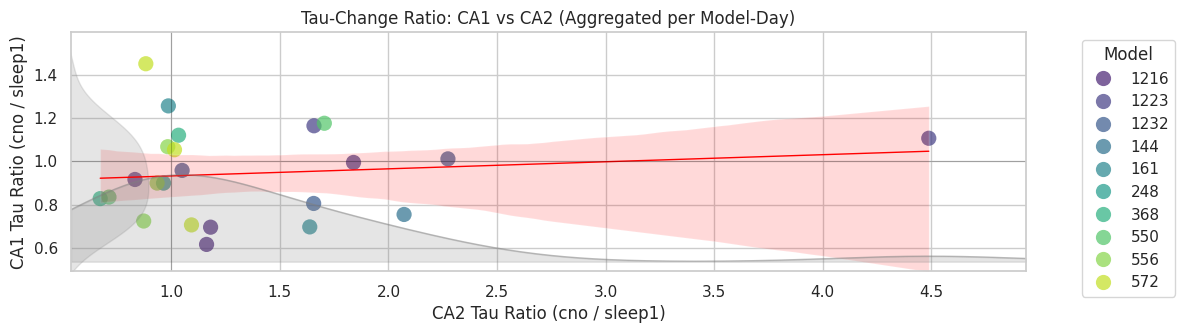

In [84]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

# 1. Label the States
result_df['State'] = result_df['Session'].apply(
    lambda s: 'sleep1' if s == 'sleep1' else ('cno' if str(s).startswith('cno') else None)
)

# 2. Aggregate within each Model-Day-Area-State
# This averages all tetrodes within an area for that specific animal on that day
df_daily_avg = result_df.dropna(subset=['State']).groupby(
    ['Model', 'Day', 'Area', 'State']
)['Tau'].mean().reset_index()

# 3. Pivot States: Get 'sleep1' and 'cno' as columns
df_state = df_daily_avg.pivot_table(
    index=['Model', 'Day', 'Area'], 
    columns='State', 
    values='Tau'
).reset_index()

# Calculate the Tau-Change Ratio (Sleep / CNO)
df_state = df_state.dropna(subset=['sleep1', 'cno'])
df_state['Tau_Ratio'] = df_state['cno'] / df_state['sleep1']

# 4. Pivot Area: Get CA1 and CA2 as columns (X and Y axes)
df_plot = df_state.pivot_table(
    index=['Model', 'Day'], 
    columns='Area', 
    values='Tau_Ratio'
).reset_index().dropna(subset=['CA1', 'CA2'])

# 5. Setup Figure
fig, ax = plt.subplots(figsize=(12, 8))

# 6. Main Scatter Plot (Viridis, no outlines)
sns.scatterplot(
    data=df_plot, x='CA2', y='CA1', hue='Model', 
    palette='viridis', s=120, linewidth=0, alpha=0.7, ax=ax
)

# 7. Regression Line (Replacing the diagonal)
sns.regplot(
    data=df_plot, x='CA2', y='CA1', scatter=False, 
    color='red', line_kws={'lw': 1, 'ls': '-'}, ax=ax
)

# 8. Internal Density Curves
def draw_internal_density(data, ax, vmin, vmax, orientation='x', color='gray', scale=0.4):
    """
    Calculates KDE and plots it as a filled polygon 
    anchored to the edge of the current plot.
    """
    kde = gaussian_kde(data)
    # Use the requested -2 to 2 range
    support = np.linspace(vmin, vmax, 200)
    density = kde(support)
    
    # Scale density to occupy a fraction of the plot area
    density_scaled = (density / density.max()) * scale
    
    if orientation == 'x': # Bottom Curve (for CA1)
        # Shifted to sit on the y=-2 line
        ax.fill_between(support, vmin, vmin + density_scaled, color=color, alpha=0.2)
        ax.plot(support, vmin + density_scaled, color=color, lw=1, alpha=0.5)
    else: # Left Curve (for CA2)
        # Shifted to sit on the x=-2 line
        ax.fill_betweenx(support, vmin, vmin + density_scaled, color=color, alpha=0.2)
        ax.plot(-2 + density_scaled, support, color=color, lw=1, alpha=0.5)

# 9. Square Aspect and Limits
# Force the limits to be identical for a true square comparison
all_vals = pd.concat([df_plot['CA1'], df_plot['CA2']])
min_v, max_v = all_vals.min() * 0.8, all_vals.max() * 1.1

# or, if the data is skewed:
min_v_x, max_v_x =  df_plot['CA2'].min() * 0.8,  df_plot['CA2'].max() * 1.1
min_v_y, max_v_y =  df_plot['CA1'].min() * 0.8,  df_plot['CA1'].max() * 1.1

draw_internal_density(df_plot['CA2'], ax, min_v_x, max_v_x, orientation='x')
draw_internal_density(df_plot['CA1'], ax, min_v_y, max_v_y, orientation='y')

ax.set_xlim(min_v_x, max_v_x)
ax.set_ylim(min_v_y, max_v_y)
ax.set_aspect('equal', adjustable='box')

# Add Unity Lines at Ratio = 1
ax.axhline(1, color='black', lw=0.5, alpha=0.3)
ax.axvline(1, color='black', lw=0.5, alpha=0.3)

# Labels
plt.xlabel('CA2 Tau Ratio (cno / sleep1)')
plt.ylabel('CA1 Tau Ratio (cno / sleep1)')
plt.title('Tau-Change Ratio: CA1 vs CA2 (Aggregated per Model-Day)')
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [72]:
result_df['State']

0          cno
1          cno
2          cno
3       sleep1
4          cno
         ...  
7627       cno
7628       cno
7630    sleep1
7631       cno
7632    sleep1
Name: State, Length: 7078, dtype: object

In [24]:
baseline_criticality_df = result_df[result_df['Session'] == 'sleep1']
baseline_criticality_df = baseline_criticality_df.groupby(['Model', 'Day', 'Area', 'Tetrode']).agg({
    'Tau': 'mean',
    'Branching_factor': 'mean'
    }).reset_index()

In [25]:
# --- STEP 1: DATA CLEANING (The "Safety" Step) ---
# Ensuring all matching keys are strings and stripped of hidden spaces
match_cols = ['Model', 'Day', 'Area', 'Tetrode', 'Timechunk']
for col in match_cols:
    if col in result_df.columns:
        result_df[col] = result_df[col].astype(str).str.strip()

print(f"Unique Areas found: {result_df['Area'].unique()}")
print("--- Cleaning Complete ---\n")

# --- STEP 2: BASELINE CRITICALITY (Sleep 1) ---
# Average Tau per Tetrode during Sleep 1
baseline_crit_df = result_df[result_df['Session'] == 'sleep1'].groupby(
    ['Model', 'Day', 'Area', 'Tetrode']).agg({
    'Tau': 'mean',
    'Branching_factor': 'mean'
    }).reset_index().rename(columns={'Tau': 'baseline_tau', 'Branching_factor': 'baseline_bf'})

print(f"Baseline Tau calculated for {len(baseline_crit_df)} unique tetrodes.")


# --- STEP 3: CA2 ACTIVITY BASELINES ---
# Filter for CA2 only
ca2_only = result_df[result_df['Area'] == 'CA2'].copy()

# A) Current CA2 Activity (CNO Sessions): Sum activity over tetrodes per Timechunk
ca2_act_post = ca2_only[ca2_only['Session'].str.startswith('cno')].groupby(
    ['Model', 'Day', 'Timechunk']
    ).agg({
    'Activity': 'sum'
    }).reset_index().rename(columns={'Activity': 'current_ca2_activity'})


# B) Baseline CA2 Activity (Sleep 1): 
# First, sum activity over tetrodes per timechunk in Sleep 1
ca2_act_pre_chunks = ca2_only[ca2_only['Session'] == 'sleep1'].groupby(
    ['Model', 'Day', 'Timechunk']).agg({
    'Activity': 'sum'
    }).reset_index()
    
# Second, average those timechunk-sums to get a single baseline value per Day
ca2_act_pre = ca2_act_pre_chunks.groupby(['Model', 'Day']).agg({
    'Activity': 'mean'
    }).reset_index().rename(
    columns={'Activity': 'baseline_ca2_activity'})

print(f"CA2 Baselines created. Post-chunks: {len(ca2_act_post)}, Pre-averages: {len(ca2_act_pre)}")



# --- STEP 4: MERGING & CALCULATION ---
# Start with the main CNO data
final_df = result_df[result_df['Session'].str.startswith('cno')].copy()

# Merge Baseline Tau (Tetrode-specific)
final_df = final_df.merge(baseline_crit_df, on=['Model', 'Day', 'Area', 'Tetrode'], how='left')

# Merge Current CA2 Activity (Timechunk-specific)
final_df = final_df.merge(ca2_act_post, on=['Model', 'Day', 'Timechunk'], how='left')

# Merge Baseline CA2 Activity (Day-specific)
final_df = final_df.merge(ca2_act_pre, on=['Model', 'Day'], how='left')

# Perform the calculations
final_df['tau_percentage'] = final_df['Tau'] / final_df['baseline_tau']
final_df['ca2_activity_percentage'] = final_df['current_ca2_activity'] / final_df['baseline_ca2_activity']

# --- STEP 5: FINAL DIAGNOSTICS ---
missing_tau = final_df['baseline_tau'].isna().sum()
missing_ca2 = final_df['current_ca2_activity'].isna().sum()

print("\n--- Final Results ---")
print(f"Total CNO rows processed: {len(final_df)}")
print(f"Rows missing Tau baseline: {missing_tau}")
print(f"Rows missing CA2 Activity: {missing_ca2}")

Unique Areas found: ['CA1' 'CA3' 'CA2']
--- Cleaning Complete ---

Baseline Tau calculated for 34 unique tetrodes.
CA2 Baselines created. Post-chunks: 18, Pre-averages: 3

--- Final Results ---
Total CNO rows processed: 808
Rows missing Tau baseline: 295
Rows missing CA2 Activity: 664


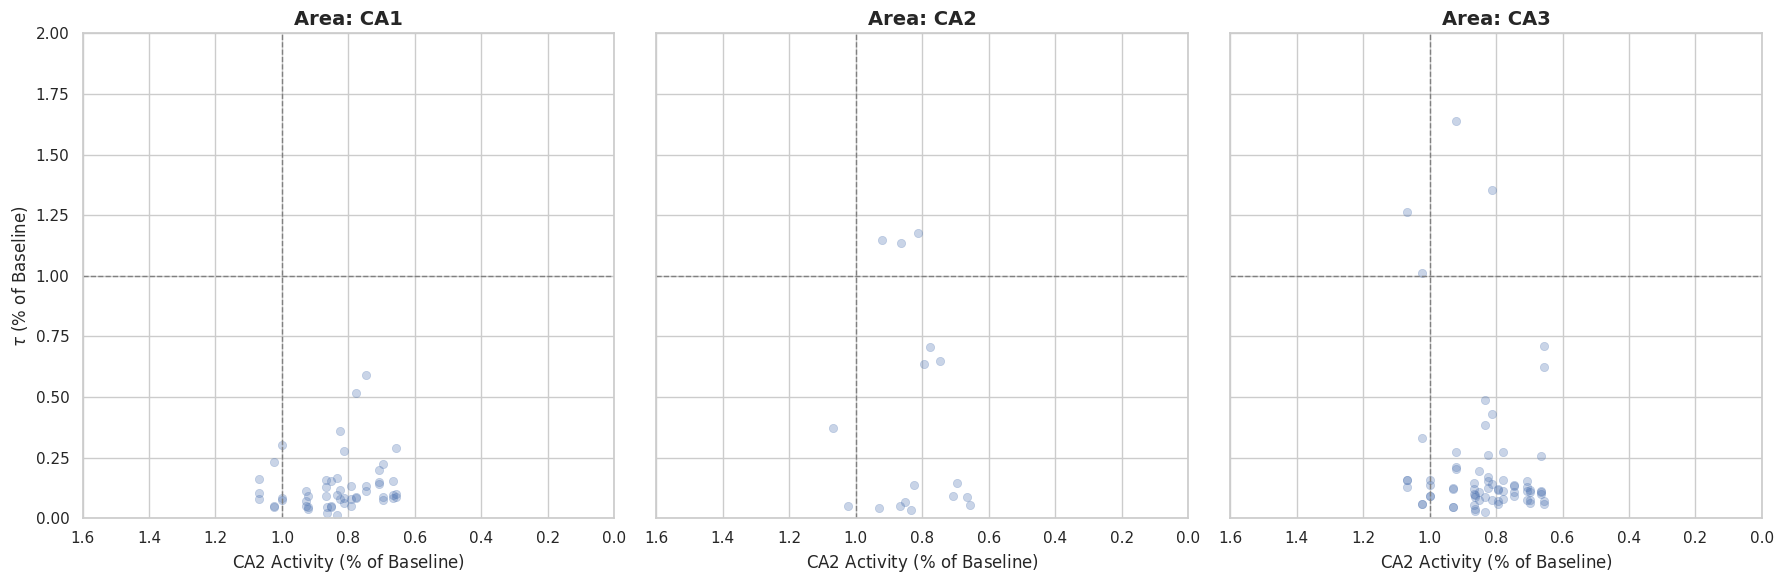

In [40]:
%matplotlib inline

upper_tau_change = 2

###

# Ensure we are only plotting rows where we actually have both percentages
plot_df = final_df.dropna(subset=['tau_percentage', 'ca2_activity_percentage'])
plot_df = plot_df[plot_df['tau_percentage'] < upper_tau_change]


# Set the visual style
sns.set_theme(style="whitegrid")

# Create a figure with 3 subplots (1 for each Area)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, sharex=True)
areas = ['CA1', 'CA2', 'CA3']

for i, area in enumerate(areas):
    # Filter data for the specific area
    subset = plot_df[plot_df['Area'] == area]
    
    # Create the scatter plot
    sns.scatterplot(
        data=subset,
        x='ca2_activity_percentage',
        y='tau_percentage',
        ax=axes[i],
        alpha=0.3,
        edgecolor=None
    )
    
    # Add a reference line at 1.0 (100%) for both axes
    axes[i].axvline(1, color='gray', linestyle='--', linewidth=1)
    axes[i].axhline(1, color='gray', linestyle='--', linewidth=1)
    
    # Titles and Labels
    axes[i].set_title(f'Area: {area}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('CA2 Activity ($\%$ of Baseline)', fontsize=12)
    
    # Only label the first y-axis since they share it
    if i == 0:
        axes[i].set_ylabel(r'$\tau$ ($\%$ of Baseline)', fontsize=12)


for ax in axes: ax.set_xlim(0, 1.6)
for ax in axes: ax.set_ylim(0, 2)
for ax in axes: ax.invert_xaxis()

plt.tight_layout()

In [27]:
final_df

,Model,Day,Session,Area,Tetrode,Timechunk,Filename,Tau,Branching_factor,Activity,baseline_tau,baseline_bf,current_ca2_activity,baseline_ca2_activity,tau_percentage,ca2_activity_percentage
0,587,09,cno2,CA1,6,028,587_09_cno2_CA1_6_028.parquet,60.333012,0.983562,8318,NaN,NaN,NaN,NaN,NaN,NaN
1,587,09,cno2,CA1,1,008,587_09_cno2_CA1_1_008.parquet,12.534749,0.923321,3901,NaN,NaN,NaN,NaN,NaN,NaN
2,587,09,cno2,CA1,2,038,587_09_cno2_CA1_2_038.parquet,255.267863,0.996090,7388,NaN,NaN,NaN,NaN,NaN,NaN
3,1212,13,cno,CA3,7,009,1212_13_cno_CA3_7_009.parquet,120.088279,0.991707,1807,322.449076,0.966656,NaN,NaN,0.372426,NaN
4,0280,11,cno,CA3,3,008,0280_11_cno_CA3_3_008.parquet,1665.360853,0.999400,1872,312.842218,0.991296,8779.0,10303.25,5.323325,0.852061
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
803,0280,11,cno,CA3,7,003,0280_11_cno_CA3_7_003.parquet,27.255254,0.963975,3213,238.300960,0.986779,NaN,10303.25,0.114373,NaN
804,0280,11,cno,CA3,3,013,0280_11_cno_CA3_3_013.parquet,37.967336,0.974005,1440,312.842218,0.991296,8173.0,10303.25,0.121363,0.793245
805,587,09,cno2,CA1,6,037,587_09_cno2_CA1_6_037.parquet,517.083195,0.998068,6268,NaN,NaN,NaN,NaN,NaN,NaN
806,1212,13,cno,CA3,7,016,1212_13_cno_CA3_7_016.parquet,2160.505644,0.999537,1595,322.449076,0.966656,NaN,NaN,6.700300,NaN


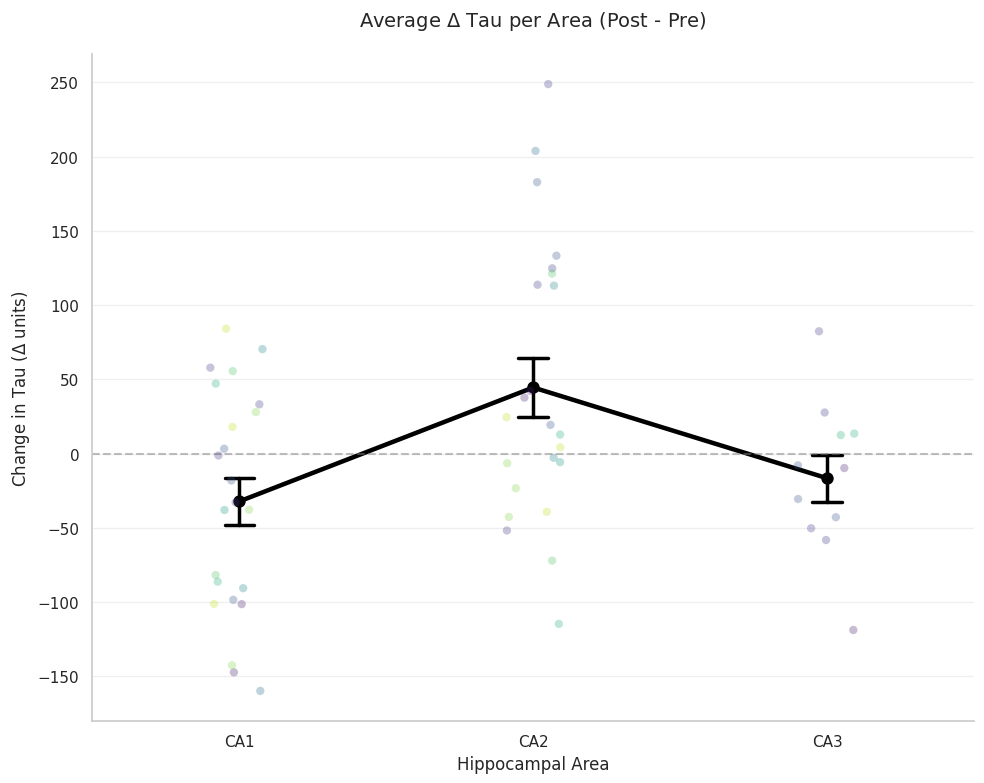

In [92]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd


result_df['State'] = result_df['Session'].apply(
    lambda s: 'sleep1' if s == 'sleep1' else ('cno' if str(s).startswith('cno') else None)
)
# 1. Aggregate to one pre and post value per Animal-Day-Area
df_agg = result_df.groupby(['Model', 'Day', 'Area', 'State'])['Tau'].mean().reset_index()

# 2. Pivot to calculate the difference
df_pivot = df_agg.pivot_table(
    index=['Model', 'Day', 'Area'], 
    columns='State', 
    values='Tau'
).reset_index()

df_pivot['tau_diff'] = df_pivot['cno'] - df_pivot['sleep1']

# 3. Filter and set order for CA1, CA2, CA3
target_areas = ["CA1", "CA2", "CA3"]
df_plot = df_pivot[df_pivot['Area'].isin(target_areas)].copy()
df_plot['Area'] = pd.Categorical(df_plot['Area'], categories=target_areas, ordered=True)

# 4. Create the Point Plot (Mean connected by lines + SE Bars)
plt.figure(figsize=(10, 8))
ax = plt.gca()

# Show the mean and Standard Error (SE) as vertical bars
sns.pointplot(
    data=df_plot, 
    x='Area', 
    y='tau_diff', 
    errorbar='se',      # Use Standard Error
    capsize=0.1,        # Horizontal caps on the error bars
    color='black',      # Line and mean point color
    markers='o',        # Circle markers for the mean
    scale=1.2,          # Size of markers/lines
    errwidth=2.5,       # Thickness of error bars
    ax=ax
)

# Overlay individual animal-day points for transparency
sns.stripplot(
    data=df_plot, x='Area', y='tau_diff', hue='Model', 
    palette='viridis', alpha=0.3, size=6, dodge=False, legend=False
)

# Reference line for zero change
plt.axhline(0, color='gray', lw=1.5, ls='--', alpha=0.5)

# Formatting
plt.title(r'Average $\Delta$ Tau per Area (Post - Pre)', fontsize=14, pad=20)
plt.ylabel(r'Change in Tau ($\Delta$ units)', fontsize=12)
plt.xlabel('Hippocampal Area', fontsize=12)

# Styling
sns.despine()
plt.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# statistical analysis

In [ ]:
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 1. Perform the One-Way ANOVA
# Assuming 'df' has columns 'subregion' and 'tau_level'
groups = [group['Tau'].values for name, group in result_df.groupby('Area')]
f_stat, p_val = stats.f_oneway(*groups)

print(f"ANOVA Result: F={f_stat:.2f}, p-value={p_val:.4f}")

# 2. If p < 0.05, perform Post-hoc Tukey HSD
if p_val < 0.05:
    print("Significant difference found. Running Tukey HSD...")
    tukey = pairwise_tukeyhsd(endog=result_df['Tau'], 
                              groups=result_df['Area'], 
                              alpha=0.05)
    print(tukey)
else:
    print("No significant difference detected.")

# 1. Perform the One-Way ANOVA
# Assuming 'df' has columns 'subregion' and 'tau_level'
groups = [group['Tau'].values for name, group in result_df.groupby('Area')]
f_stat, p_val = stats.f_oneway(*groups)

print(f"ANOVA Result: F={f_stat:.2f}, p-value={p_val:.4f}")

# 2. If p < 0.05, perform Post-hoc Tukey HSD
if p_val < 0.05:
    print("Significant difference found. Running Tukey HSD...")
    tukey = pairwise_tukeyhsd(endog=result_df['Tau'], 
                              groups=result_df['Area'], 
                              alpha=0.05)
    print(tukey)
else:
    print("No significant difference detected.")

ANOVA Result: F=20.40, p-value=0.0000
Significant difference found. Running Tukey HSD...


NameError: name 'df' is not defined